# What the stats say a player is worth

The market price is the target, not an input. For every player-season from 2022-23 through 2025-26 with at least 900 minutes, a Transfermarkt id, and a season-end fee, we predict log(fee) from age, minutes, league, role, playing style, and the per-90 stats. Goals and assists are included here. They were left out of the style clusters because a goal is a result, but a result is exactly what a fee pays for.

Each row is scored by a model that never saw that player. The gap is predicted fee divided by actual fee. A gap of 2 means the stats imply twice the market price.

## Two ways to miss

Ridge is the plain model: a straight line in the scaled features, with the penalty chosen by cross-validation. Gradient boosting is the flexible one. It can bend.

We score both twice. In the grouped test, the same player is never in both the training fold and the test fold, so the model cannot memorize him from another season. In the time split, the model trains on 2022-23 through 2024-25 and is tested on 2025-26, a season it has never seen.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.value_model import (
    build_modeling_frame,
    choose_model,
    evaluate_models,
    out_of_fold_predictions,
    ridge_effects,
    top_undervalued,
)

LEAGUES = {
    "ENG-Premier League": "Premier League",
    "ESP-La Liga": "La Liga",
    "GER-Bundesliga": "Bundesliga",
    "ITA-Serie A": "Serie A",
    "FRA-Ligue 1": "Ligue 1",
}
ROLE_ORDER = ["CB", "FB", "CM", "AM_W", "ST"]
ROLE_TITLE = {
    "CB": "Centre-backs",
    "FB": "Fullbacks",
    "CM": "Central midfielders",
    "AM_W": "Attacking midfielders and wingers",
    "ST": "Strikers",
}

def money(value):
    return f"€{value / 1e6:.1f}m"

modeling = build_modeling_frame()
comparison = evaluate_models(modeling)
winner, reason = choose_model(comparison)
shown = comparison.copy()
shown["model"] = shown["model"].map(
    {"ridge": "Ridge", "hist_gradient_boosting": "Gradient boosting"}
)
shown = shown.rename(
    columns={
        "model": "Model",
        "split": "Test",
        "r2": "R²",
        "mae_log": "MAE (log fee)",
        "median_abs_pct_error": "Median abs % error",
    }
)
shown["R²"] = shown["R²"].round(3)
shown["MAE (log fee)"] = shown["MAE (log fee)"].round(3)
shown["Median abs % error"] = shown["Median abs % error"].round(1)
display(shown)
print(reason)
print(f"{len(modeling)} player-seasons in the fit.")
predictions = out_of_fold_predictions(modeling, winner)


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot


,Model,Test,R²,MAE (log fee),Median abs % error
0,Ridge,GroupKFold,0.609,0.600,48.7
1,Ridge,time split 2025-26,0.619,0.586,45.6
2,Gradient boosting,GroupKFold,0.595,0.611,49.1
3,Gradient boosting,time split 2025-26,0.620,0.586,45.3


On the 2025-26 season neither model trained on, the median errors are 45.6% for Ridge and 45.3% for gradient boosting. That is a tie. The player-grouped test breaks it: Ridge's median error is 48.7% and its R² is 0.61, against 49.1% and 0.59 for gradient boosting. We keep Ridge.
5657 player-seasons in the fit.


## Predicted fee against the real fee

Both axes are on a log scale, so a player at €2m and a player at €80m can share the chart. The line is a perfect prediction. Points above the line are the ones whose stats imply a higher fee than the market. Tottenham's 2025-26 regulars are ringed.

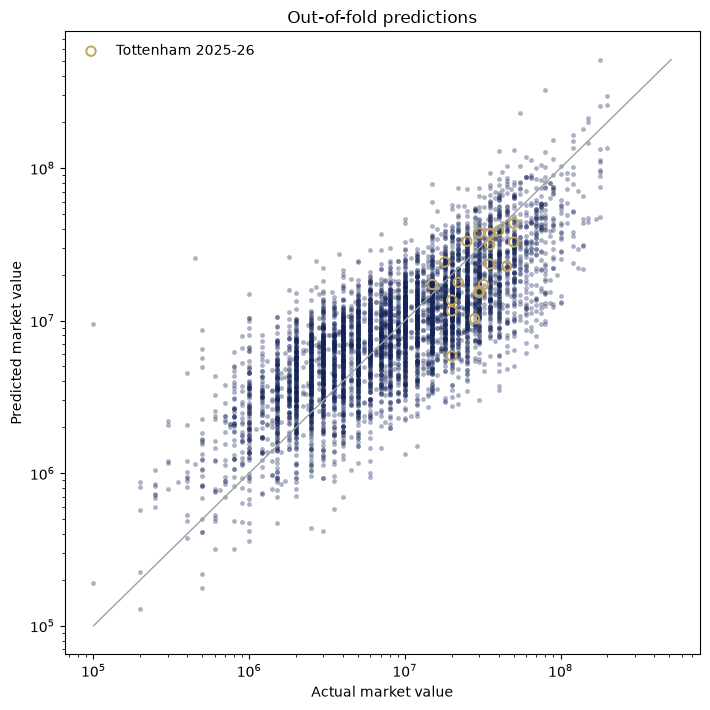

In [2]:
fig, ax = plt.subplots(figsize=(7.2, 7.2))
ax.scatter(
    predictions["actual_value"],
    predictions["predicted_value"],
    s=12,
    alpha=0.35,
    color="#132257",
    linewidths=0,
)
spurs = predictions.loc[(predictions["team"] == "Tottenham") & (predictions["season"] == 2526)]
ax.scatter(
    spurs["actual_value"],
    spurs["predicted_value"],
    s=46,
    facecolors="none",
    edgecolors="#C4A35A",
    linewidths=1.4,
    zorder=3,
    label="Tottenham 2025-26",
)
span = [
    predictions[["actual_value", "predicted_value"]].min().min(),
    predictions[["actual_value", "predicted_value"]].max().max(),
]
ax.plot(span, span, color="#9aa0a6", linewidth=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual market value")
ax.set_ylabel("Predicted market value")
ax.set_title("Out-of-fold predictions")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## What the straight-line model is paying for

These are Ridge's ten largest coefficients, fit on 2022-23 through 2024-25 only. They are associations, holding the other stats fixed. The age line is the combined effect of age and age-squared at 25. A per-90 effect is for an extra tenth of that action per 90 minutes. The league effects are versus the Premier League, and the striker effect is versus a centre-back with the same counting stats.

In [3]:
effects = ridge_effects(modeling)
display(effects[["feature", "in_words"]].rename(columns={"feature": "Feature", "in_words": "In words"}))


,Feature,In words
0,age_sq,"Age-squared bends that curve, so the age effec..."
1,age,"At age 25, one more year changes value by abou..."
2,league_FRA-Ligue 1,Ligue 1 rather than the Premier League is asso...
3,league_GER-Bundesliga,the Bundesliga rather than the Premier League ...
4,league_ITA-Serie A,Serie A rather than the Premier League is asso...
5,league_ESP-La Liga,La Liga rather than the Premier League is asso...
6,position_group_ST,A ST rather than a centre-back is associated w...
7,shots_per90,An extra 0.1 per 90 of shots is associated wit...
8,assists_per90,An extra 0.1 per 90 of assists is associated w...
9,goals_per90,An extra 0.1 per 90 of goals is associated wit...


## Undervalued in 2025-26, aged 27 or under

Ten players in each role, largest gap first. The fee is the June 2026 Transfermarkt value. A very small fee produces a very large gap, so the top of a list can be a player the market has barely priced rather than a star the market has missed.

In [4]:
def show_shortlist(position_group):
    hits = top_undervalued(position_group=position_group, max_age=27, n=10, predictions=predictions)
    table = pd.DataFrame(
        {
            "Player": hits["player"],
            "Team": hits["team"],
            "League": hits["league"].map(LEAGUES).fillna(hits["league"]),
            "Age": hits["age"].round(0).astype("Int64"),
            "Style": hits["style_cluster"],
            "Actual": hits["actual_value"].map(money),
            "Predicted": hits["predicted_value"].map(money),
            "Gap": hits["value_gap"].map(lambda value: f"{value:.2f}x"),
        }
    )
    print(ROLE_TITLE[position_group])
    display(table.reset_index(drop=True))

for role in ROLE_ORDER:
    show_shortlist(role)


Centre-backs


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Filippo Terracciano,Cremonese,Serie A,22,Positional centre-back,€4.5m,€18.8m,4.18x
1,Lautaro Valenti,Parma,Serie A,26,Aggressive centre-back,€2.0m,€8.3m,4.15x
2,Alan Matturro,Levante,La Liga,20,Positional centre-back,€4.0m,€16.3m,4.08x
3,Alejandro Francés,Girona,La Liga,22,Aggressive centre-back,€3.0m,€11.5m,3.83x
4,Zaid Romero,Getafe,La Liga,25,Aggressive centre-back,€2.5m,€9.3m,3.73x
5,Eray Cömert,Valencia,La Liga,27,Positional centre-back,€2.5m,€9.1m,3.66x
6,Simone Canestrelli,Pisa,Serie A,24,Positional centre-back,€4.5m,€15.5m,3.45x
7,Hjalmar Ekdal,Burnley,Premier League,26,Positional centre-back,€5.0m,€17.2m,3.44x
8,Tim Siersleben,Heidenheim,Bundesliga,25,Aggressive centre-back,€1.8m,€5.4m,2.99x
9,Santiago Bueno,Wolves,Premier League,26,Positional centre-back,€10.0m,€28.9m,2.89x


Fullbacks


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Danilo Veiga,Lecce,Serie A,22,Defensive fullback,€2.5m,€11.6m,4.63x
1,William Mikelbrencis,Hamburger SV,Bundesliga,21,Attacking wing-back,€3.0m,€13.7m,4.56x
2,Domagoj Bradarić,Hellas Verona,Serie A,25,Holding fullback,€1.5m,€6.6m,4.40x
3,Fodé Doucouré,Le Havre,Ligue 1,24,Attacking wing-back,€2.0m,€8.8m,4.39x
4,Giorgi Gocholeishvili,Hamburger SV,Bundesliga,24,Attacking wing-back,€2.0m,€7.4m,3.71x
5,Lucas,Burnley,Premier League,24,Attacking wing-back,€4.0m,€13.6m,3.41x
6,Fredrik Oppegard,Auxerre,Ligue 1,22,Holding fullback,€1.5m,€5.1m,3.39x
7,Arkadiusz Pyrka,St Pauli,Bundesliga,22,Holding fullback,€3.5m,€11.6m,3.31x
8,Hannes Behrens,Heidenheim,Bundesliga,20,Attacking wing-back,€5.0m,€16.5m,3.30x
9,Antonino Gallo,Lecce,Serie A,25,Holding fullback,€3.5m,€10.8m,3.09x


Central midfielders


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Oliver Jensen,Parma,Serie A,23,Screening midfielder,€0.1m,€9.5m,95.16x
1,Julian Niehues,Heidenheim,Bundesliga,24,Screening midfielder,€1.5m,€9.1m,6.09x
2,Olasagasti,Levante,La Liga,24,Wide midfielder,€2.5m,€13.6m,5.44x
3,Martim Neto,Elche,La Liga,22,Screening midfielder,€4.0m,€21.3m,5.32x
4,Kervin Arriaga,Levante,La Liga,27,Ball-winning destroyer,€2.0m,€9.9m,4.97x
5,Jan Schöppner,Heidenheim,Bundesliga,26,Screening midfielder,€3.0m,€12.0m,4.00x
6,Alberto Reina,Oviedo,La Liga,27,Arriving midfielder,€2.0m,€7.3m,3.64x
7,Youssef Maleh,Cremonese,Serie A,26,Ball-winning destroyer,€1.5m,€5.2m,3.48x
8,Kwasi Sibo,Oviedo,La Liga,27,Screening midfielder,€1.4m,€4.7m,3.39x
9,Ramón Terrats,Espanyol,La Liga,24,Ball-winning destroyer,€3.0m,€9.5m,3.16x


Attacking midfielders and wingers


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Kareem Tunde,Levante,La Liga,19,Tracking winger,€2.0m,€10.2m,5.12x
1,Ilyas Chaira,Oviedo,La Liga,24,Foul-drawing winger,€4.0m,€17.1m,4.27x
2,Ángel Pérez,Alavés,La Liga,22,Crossing winger,€3.0m,€11.3m,3.78x
3,Bakery Jatta,Hamburger SV,Bundesliga,27,Tracking winger,€1.0m,€3.8m,3.78x
4,Lameck Banda,Lecce,Serie A,24,Foul-drawing winger,€3.5m,€12.5m,3.57x
5,Víctor García,Levante,La Liga,27,Crossing winger,€1.5m,€4.8m,3.18x
6,Marcus Edwards,Burnley,Premier League,26,Inside forward,€6.0m,€18.2m,3.03x
7,Adrián Liso,Getafe,La Liga,20,Foul-drawing winger,€3.0m,€9.1m,3.03x
8,Mehdi Léris,Pisa,Serie A,27,Tracking winger,€1.8m,€5.1m,2.84x
9,Pablo Pagis,Lorient,Ligue 1,22,Crossing winger,€15.0m,€41.3m,2.76x


Strikers


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Raúl,Osasuna,La Liga,24,Dropping forward,€3.0m,€18.1m,6.03x
1,Iker Losada,Levante,La Liga,23,Dropping forward,€1.8m,€7.7m,4.27x
2,Mateo Joseph,Mallorca,La Liga,21,Dropping forward,€3.5m,€12.3m,3.50x
3,Santiago Hidalgo,Toulouse,Ligue 1,20,Pressing striker,€6.0m,€19.4m,3.24x
4,Gift Orban,Hellas Verona,Serie A,23,Penalty-box striker,€7.0m,€21.8m,3.11x
5,Vitinha,Genoa,Serie A,25,Dropping forward,€8.0m,€23.7m,2.97x
6,Luis Vázquez,Getafe,La Liga,24,Pressing striker,€2.5m,€7.3m,2.93x
7,Goduine Koyalipou,Angers,Ligue 1,25,Penalty-box striker,€2.5m,€6.9m,2.77x
8,Tosin Aiyegun,Lorient,Ligue 1,27,Penalty-box striker,€1.8m,€4.7m,2.62x
9,Andrej Ilic,Union Berlin,Bundesliga,25,Penalty-box striker,€9.0m,€22.0m,2.45x


## Where Spurs sit

A gap above 1 means the stats imply more than the fee. A gap below 1 means the market is paying more than these stats support. The three names at each end of the squad list are the ones to talk about.

In [5]:
squad = predictions.loc[(predictions["team"] == "Tottenham") & (predictions["season"] == 2526)].copy()
squad = squad.sort_values("value_gap", ascending=False)
table = pd.DataFrame(
    {
        "Player": squad["player"],
        "Role": squad["position_group"],
        "Age": squad["age"].round(0).astype("Int64"),
        "Style": squad["style_cluster"],
        "Actual": squad["actual_value"].map(money),
        "Predicted": squad["predicted_value"].map(money),
        "Gap": squad["value_gap"].map(lambda value: f"{value:.2f}x"),
    }
)
display(table.reset_index(drop=True))
richest = squad.nlargest(3, "value_gap")
dearest = squad.nsmallest(3, "value_gap")
print("Largest gaps (stats ahead of the fee):")
for row in richest.itertuples(index=False):
    print(f"  {row.player}: {row.value_gap:.2f}x, fee {money(row.actual_value)}, model {money(row.predicted_value)}")
print("Smallest gaps (fee ahead of the stats):")
for row in dearest.itertuples(index=False):
    print(f"  {row.player}: {row.value_gap:.2f}x, fee {money(row.actual_value)}, model {money(row.predicted_value)}")


,Player,Role,Age,Style,Actual,Predicted,Gap
0,Wilson Odobert,AM_W,20,Inside forward,€18.0m,€24.2m,1.34x
1,Richarlison,ST,28,Dropping forward,€25.0m,€33.1m,1.32x
2,Pape Matar Sarr,CM,22,Ball-winning destroyer,€30.0m,€37.5m,1.25x
3,João Palhinha,CM,30,Ball-winning destroyer,€15.0m,€17.2m,1.15x
4,Archie Gray,CM,19,Screening midfielder,€35.0m,€37.1m,1.06x
5,Xavi Simons,AM_W,22,Tracking winger,€40.0m,€38.7m,0.97x
6,Lucas Bergvall,CM,19,Arriving midfielder,€35.0m,€31.5m,0.90x
7,Micky van de Ven,CB,24,Positional centre-back,€50.0m,€43.5m,0.87x
8,Mathys Tel,ST,20,Dropping forward,€22.0m,€17.8m,0.81x
9,Rodrigo Bentancur,CM,28,Screening midfielder,€20.0m,€13.6m,0.68x


Largest gaps (stats ahead of the fee):
  Wilson Odobert: 1.34x, fee €18.0m, model €24.2m
  Richarlison: 1.32x, fee €25.0m, model €33.1m
  Pape Matar Sarr: 1.25x, fee €30.0m, model €37.5m
Smallest gaps (fee ahead of the stats):
  Randal Kolo Muani: 0.29x, fee €20.0m, model €5.9m
  Dominic Solanke: 0.37x, fee €28.0m, model €10.3m
  Cristian Romero: 0.50x, fee €45.0m, model €22.7m


## Limitations

The market knows things this model cannot see: injuries, wages, contract length, character, and potential. "Undervalued" here means the stats imply more than the market pays. It is a shortlist for scouting, not a verdict.

There is still no expected goals and no passing, so a player who creates chances without scoring looks cheaper than he is. The fees are Transfermarkt's June 2026 figures, not a live price.